# Counterfactual Sampling on ColorMNIST: DR-CPME Target, IMQ-Kernel MMD Flow (Forward Euler)

Doubly robust counterfactual image sampling. The interventional image law $P(Y(a))$ is represented
by its cross-fitted doubly robust mean embedding over encoded logged outcomes, and samples are
generated by transporting particles toward this embedding with the forward-Euler MMD gradient flow
under an inverse-multiquadric kernel in the latent space of a convolutional autoencoder. The decoder
maps the transported particles back to images.

This notebook targets the **untreated arm** $a^\* = 0$ (digit class $d_0 = 1$, whose observed arm
under-represents red digits); its companion targets $a^\* = 1$. The two notebooks share an
identical configuration — data seed, confounding strength, support size, particle count, and all
hyperparameters — so the arms form a matched pair and differ only in the target intervention.

In [1]:
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

sys.path.append("../../src")
torch.set_default_dtype(torch.float32)

from data_utils import (color_ratio, load_digit_pools, sample_interventional,
                        sample_observed, to_image_range, to_model_range)
from autoencoder_utils import encode_in_batches, train_conv_ae
from kernel_utils import IMQKernel, RBF, imq_c_from_median
from causality_utils import (cpme_dr_weights_crossfit, make_crossfit_fold_ids,
                             select_regularization)
from dens_ratio_utils import crossfit_propensity
from mmd_flow_utils import mmd_gradient_flow, squared_mmd
from metric_utils import sliced_wasserstein

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 1. Data Generation

ColorMNIST design of Dance et al. (2026, Appendix B.2.4). A scalar confounder colours the digit and
drives the treatment, which selects the digit class:

$$
X \sim U[0, 1], \qquad
A \mid x \sim \mathrm{Bernoulli}\big(\sigma(w (x - \tfrac12))\big), \qquad
Y \mid x, a = \text{digit of class } d_a \text{ recoloured by } c_{\mathrm{fg}}(x),
$$

with $c_{\mathrm{fg}}(x) = (x, \alpha, 1 - x)$ on a black background, digit classes
$(d_0, d_1) = (1, 6)$, confounding strength $w = 10$, mask $(\tau, k) = (0.08, 20)$, and
$\alpha = 0.2$. The untreated arm $A = 0$ (digit class $d_0 = 1$) under-represents red digits; the interventional
law $P(Y(0))$ fixes the digit class to $d_0$ and keeps $X \sim U[0,1]$, so its colour law is
uniform. The pixel ratio
$R/(R+B)$ recovers $X$ exactly and is the scalar diagnostic of deconfounding.

n = 20000   arm a=0 size = 10077   E[X | A=0] = 0.279   (marginal E[X] = 0.5)


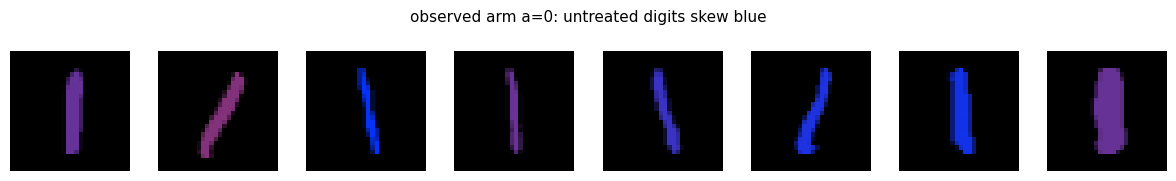

In [2]:
N_OBS, TARGET_A = 20000, 0
W_CONF, TAU = 10.0, 0.08

pools = load_digit_pools(root="../../data", device=device)
generator = torch.Generator(device=device).manual_seed(SEED)
X_obs, A_obs, Y_obs = sample_observed(pools, N_OBS, w_conf=W_CONF, tau=TAU,
                                      generator=generator)
data = to_model_range(Y_obs)
arm = A_obs == TARGET_A
print(f"n = {N_OBS}   arm a={TARGET_A} size = {int(arm.sum())}   "
      f"E[X | A={TARGET_A}] = {X_obs[arm].mean():.3f}   (marginal E[X] = 0.5)")

fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for image, ax in zip(Y_obs[arm][:8], axes):
    ax.imshow(image.permute(1, 2, 0).cpu().numpy())
    ax.axis("off")
fig.suptitle(f"observed arm a={TARGET_A}: untreated digits skew blue", fontsize=11)
fig.tight_layout()
plt.show()

## 2. Autoencoder Feature Map

A convolutional autoencoder (latent dimension 32) trained on the observed images defines the latent
space of the flow: the encoder is the feature map of the kernel, and the decoder returns transported
particles to the image manifold.

reconstruction MSE: 0.0025


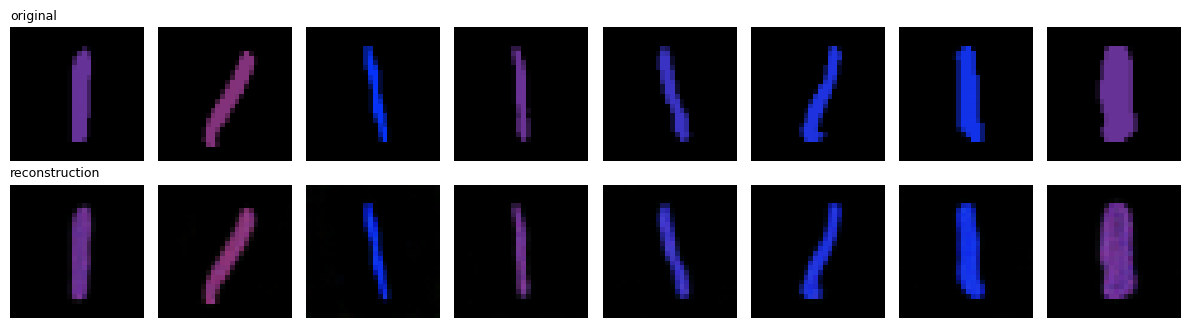

In [3]:
ae, history_ae = train_conv_ae(data, latent_dim=32, n_iterations=3000, batch_size=128,
                               learning_rate=1e-3, device=device,
                               generator=torch.Generator(device=device).manual_seed(SEED),
                               log_every=1500, verbose=False)
for parameter in ae.parameters():
    parameter.requires_grad_(False)
print(f"reconstruction MSE: {history_ae[-1][1]:.4f}")

with torch.no_grad():
    recon = ae(data[arm][:8])
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for k in range(8):
    axes[0, k].imshow(Y_obs[arm][k].permute(1, 2, 0).cpu().numpy())
    axes[1, k].imshow(to_image_range(recon[k]).permute(1, 2, 0).cpu().numpy())
    for row in (0, 1):
        axes[row, k].axis("off")
axes[0, 0].set_title("original", fontsize=9, loc="left")
axes[1, 0].set_title("reconstruction", fontsize=9, loc="left")
fig.tight_layout()
plt.show()

## 3. Cross-Fitted DR Weight Fitting

The interventional embedding under $A = a^\*$ is a finite expansion over $n_{\mathrm{DR}}$ encoded
logged outcomes, $\hat\chi(a^\*) = \sum_i v_i\, k_Y(z_i, \cdot)$, with the cross-fitted one-step
doubly robust weights

$$
v_{\mathrm{DR}} = \tfrac1n (K + \lambda I)^{-1} (K_X \circ K_A^{a^\*}) \mathbf 1
\; + \; \tfrac1n \big[\hat w - (K + \lambda I)^{-1} K \hat w\big],
\qquad
\hat w_i = \frac{\mathbf 1\{a_i = a^\*\}}{\hat e_{a^\*}(x_i)} .
$$

All nuisances share one 5-fold split: the plug-in logistic propensity
(`dens_ratio_utils.LogisticPropensityModel`, well specified since the true propensity is logistic in
$x$), the conditional mean embedding behind both terms, and the per-fold ridge $\lambda_k$. The
kernel on the binary treatment is the delta kernel; the kernel on the confounder is a
median-heuristic RBF. The support is an $n_{\mathrm{DR}} = 4000$ subsample of the logged data, since
the conditional-mean-embedding solves are cubic in the support size.

In [4]:
N_DR = 4000
subsample = torch.randperm(N_OBS, generator=torch.Generator(device=device).manual_seed(SEED + 5),
                           device=device)[:N_DR]
X_s, A_s = X_obs[subsample], A_obs[subsample]
Z_s = encode_in_batches(ae.encode, data[subsample])

fold_ids = make_crossfit_fold_ids(N_DR, n_folds=5, seed=0)
torch.manual_seed(SEED)
e1 = crossfit_propensity(X_s.unsqueeze(1).double().cpu(), A_s.double().cpu(), fold_ids)
e_target = e1 if TARGET_A == 1 else 1.0 - e1
w_hat = (A_s.cpu() == TARGET_A).double() / e_target
on_arm = w_hat[A_s.cpu() == TARGET_A]
print(f"on-arm ESS = {(on_arm.sum() ** 2 / (on_arm ** 2).sum()).item():.0f} "
      f"of {len(on_arm)}   max weight = {w_hat.max():.1f}")

kernel_x = RBF(use_length_scale_heuristic=True)
K_x = kernel_x(X_s.unsqueeze(1).double().cpu())
K_a = (A_s[:, None] == A_s[None, :]).double().cpu()
K_a_target = (A_s == TARGET_A).double().cpu()[:, None].expand(N_DR, N_DR).contiguous()

K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_s[train, 0].double().cpu(), seed=0)
print(f"per-fold lambdas: {fold_lambdas}")

v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_hat, fold_ids,
                                fold_lambdas).float().to(device)
print(f"DR weights:  sum(v) = {v_dr.sum():.3f}   sum|v| = {v_dr.abs().sum():.3f}")

on-arm ESS = 265 of 2059   max weight = 110.6


per-fold lambdas: {0: 10.0, 1: 10.0, 2: 10.0, 3: 0.0001, 4: 10.0}


DR weights:  sum(v) = 1.003   sum|v| = 1.003


## 4. IMQ MMD Flow in the Latent Space

Particles are initialised at encoded observed arm-$a^\*$ images and transported by the forward-Euler
MMD flow toward $\hat\chi(a^\*)$ under the inverse-multiquadric kernel
$k(u, v) = (c^2 + \lVert u - v \rVert^2)^{-1/2}$, whose heavy tails keep the witness gradient alive
for far-apart points. The scale $c$ is the median pairwise distance of the support latents and the
step size is $0.15\, c^2$.

IMQ c = 13.30   step = 26.5   objective 1.19e-03 -> 6.86e-06


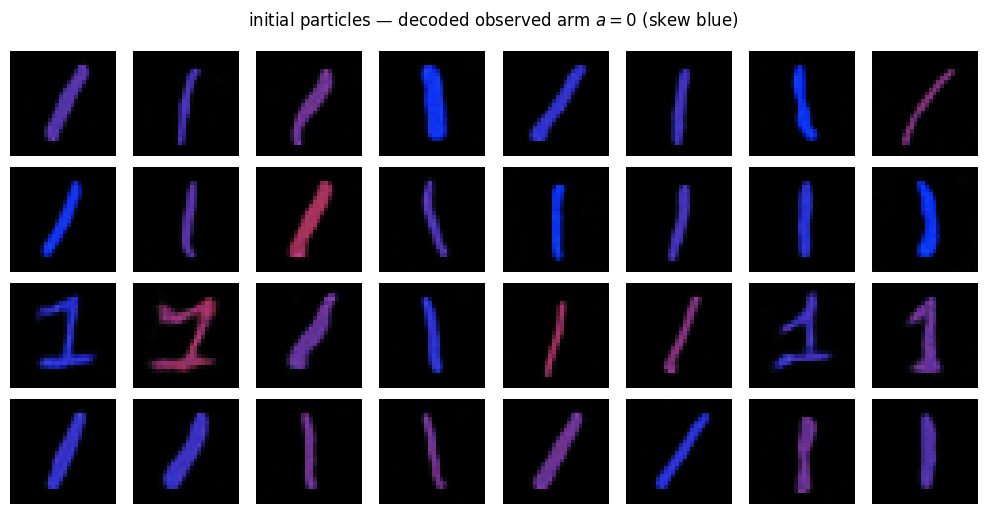

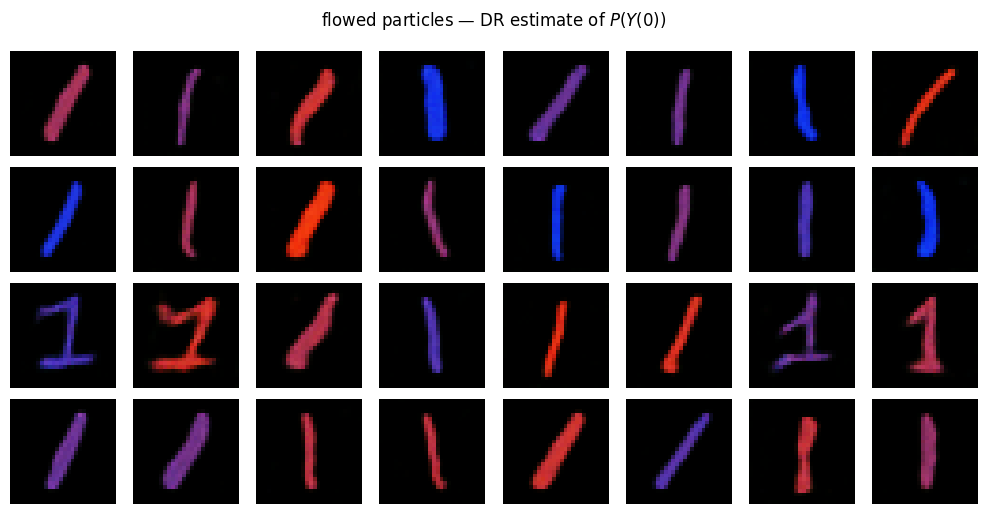

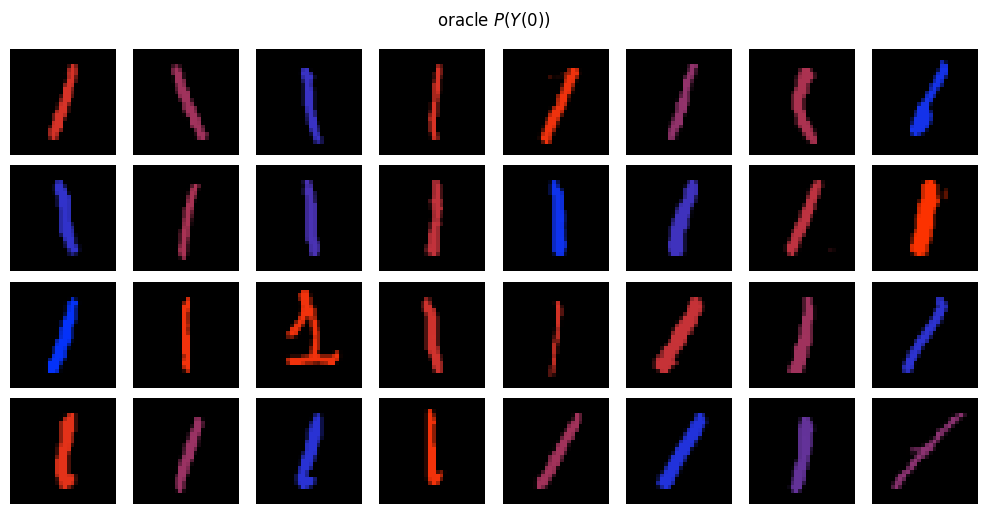

In [5]:
M = 1600
Z_arm = encode_in_batches(ae.encode, data[arm])
pick = torch.randperm(Z_arm.shape[0], generator=torch.Generator(device=device).manual_seed(SEED + 1),
                      device=device)[:M]
initial_particles = Z_arm[pick].clone()

c_imq = imq_c_from_median(Z_s)
kernel = IMQKernel(c=c_imq, beta=-0.5)
step_size = 0.15 * c_imq ** 2
particles, history = mmd_gradient_flow(kernel, target_samples=Z_s,
                                       initial_particles=initial_particles,
                                       step_size=step_size, n_iterations=3000,
                                       target_weights=v_dr, log_every=100, verbose=False)
print(f"IMQ c = {c_imq:.2f}   step = {step_size:.1f}   "
      f"objective {history['squared_mmd'][0]:.2e} -> {history['squared_mmd'][-1]:.2e}")

with torch.no_grad():
    decoded_initial = ae.decode(initial_particles)
    decoded_flowed = ae.decode(particles)
_, Y_oracle = sample_interventional(pools, M, a=TARGET_A, tau=TAU,
                                    generator=torch.Generator(device=device).manual_seed(SEED + 9))


def show_grid(images, title, in_model_range=True):
    fig, axes = plt.subplots(4, 8, figsize=(10, 5.2))
    for image, ax in zip(images[:32], axes.flatten()):
        shown = to_image_range(image) if in_model_range else image
        ax.imshow(shown.permute(1, 2, 0).cpu().numpy())
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


show_grid(decoded_initial, f"initial particles — decoded observed arm $a={TARGET_A}$ (skew blue)")
show_grid(decoded_flowed, f"flowed particles — DR estimate of $P(Y({TARGET_A}))$")
show_grid(Y_oracle, f"oracle $P(Y({TARGET_A}))$", in_model_range=False)

### Colour law

The pixel ratio $R/(R+B)$ recovers the confounder $X$, so the interventional colour law is uniform
on $[0, 1]$. Densities are shown on the logit scale.

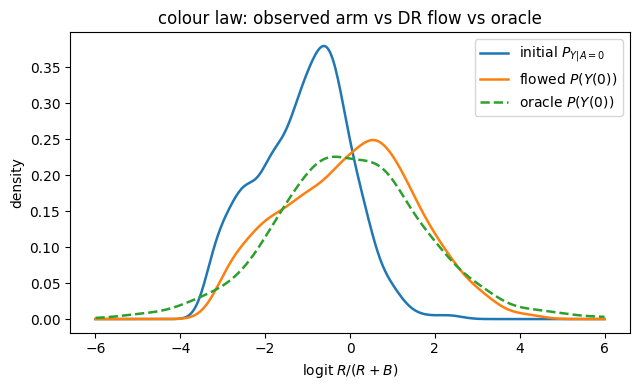

In [6]:
colour = {
    f"initial $P_{{Y|A={TARGET_A}}}$": color_ratio(to_image_range(decoded_initial)).cpu().numpy(),
    f"flowed $P(Y({TARGET_A}))$": color_ratio(to_image_range(decoded_flowed)).cpu().numpy(),
    f"oracle $P(Y({TARGET_A}))$": color_ratio(Y_oracle).cpu().numpy(),
}
logit = lambda p: np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4)))
grid = np.linspace(-6, 6, 400)
plt.figure(figsize=(6.5, 4))
for (name, values), style in zip(colour.items(), ("-", "-", "--")):
    plt.plot(grid, gaussian_kde(logit(values))(grid), lw=1.8, linestyle=style, label=name)
plt.xlabel(r"$\mathrm{logit}\; R/(R+B)$")
plt.ylabel("density")
plt.legend()
plt.title("colour law: observed arm vs DR flow vs oracle")
plt.tight_layout()
plt.show()

## 5. Metric Evaluation

Colour-ratio moments, sliced Wasserstein distances of orders 1 and 2, and unbiased squared MMD
(median-heuristic RBF on flattened pixels) between each decoded sample and an oracle draw of
$P(Y(a^\*))$; a second, independent oracle draw gives the finite-sample floors. The sliced
Wasserstein estimator follows the evaluation code of Dance et al. (2026), whose ColorMNIST results
are reported in Sliced Wasserstein-2.

In [7]:
_, Y_oracle_2 = sample_interventional(pools, M, a=TARGET_A, tau=TAU,
                                      generator=torch.Generator(device=device).manual_seed(SEED + 10))
flatten = lambda images: images.reshape(images.shape[0], -1)
kernel_pixel = RBF(use_length_scale_heuristic=True)
_ = kernel_pixel(flatten(Y_oracle))


def evaluate(images_01):
    reference = flatten(Y_oracle)
    sw1 = sliced_wasserstein(flatten(images_01), reference, p=1, seed=0).item()
    sw2 = sliced_wasserstein(flatten(images_01), reference, p=2, seed=0).item()
    mmd2 = squared_mmd(kernel_pixel, flatten(images_01), reference, unbiased=True).item()
    return sw1, sw2, mmd2


rows = {f"observed arm {TARGET_A}": to_image_range(decoded_initial),
        "DR flow": to_image_range(decoded_flowed),
        "oracle-vs-oracle floor": Y_oracle_2}
print(f"{'sample':26s} {'colour mean(std)':>18s} {'SW1':>8s} {'SW2':>8s} {'MMD^2':>10s}")
for name, images in rows.items():
    sw1, sw2, mmd2 = evaluate(images)
    ratio = color_ratio(images).cpu().numpy()
    print(f"{name:26s} {ratio.mean():>11.3f}({ratio.std():.3f}) {sw1:8.4f} {sw2:8.4f} {mmd2:10.2e}")
oracle_ratio = colour[f"oracle $P(Y({TARGET_A}))$"]
print(f"{'oracle colour reference':26s} {oracle_ratio.mean():>11.3f}({oracle_ratio.std():.3f})")

sample                       colour mean(std)      SW1      SW2      MMD^2
observed arm 0                   0.292(0.187)   0.0268   0.0357   4.02e-02
DR flow                          0.503(0.282)   0.0059   0.0086   9.19e-04
oracle-vs-oracle floor           0.494(0.286)   0.0038   0.0058  -1.14e-04
oracle colour reference          0.497(0.291)
